<a href="https://colab.research.google.com/github/Lingadarini/trendpulse/blob/part3-eda/part3_visualization_eda/part3_visualization_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone -b part3-eda https://github.com/Lingadarini/trendpulse.git
!ls trendpulse/part3_visualization_eda/data

Cloning into 'trendpulse'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 81 (delta 32), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 2.44 MiB | 4.39 MiB/s, done.
Resolving deltas: 100% (32/32), done.
categories.csv	GBvideos.csv  INvideos.csv  USvideos.csv


# Part 3 - Visualization, EDA and Business Thinking

## 1. Profile the data

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "trendpulse/part3_visualization_eda/data/"
COUNTRIES = ["US", "GB", "IN"]

# Load and combine
frames = []
for country in COUNTRIES:
    df_c = pd.read_csv(f"{DATA_DIR}{country}videos.csv")
    df_c["country"] = country
    frames.append(df_c)
raw = pd.concat(frames, ignore_index=True)

# Profile BEFORE cleaning
print("Shape:", raw.shape)
print("\nData types:")
print(raw.dtypes)

missing = raw.isna().sum()
missing = missing[missing > 0]
print("\nMissing values:")
for col, n in missing.items():
    print(f"  {col}: {n} ({n / len(raw) * 100:.2f}%)")

Shape: (46230, 17)

Data types:
video_id                   object
trending_date              object
title                      object
channel_title              object
category_id                 int64
publish_time               object
tags                       object
views                       int64
likes                     float64
dislikes                    int64
comment_count             float64
thumbnail_link             object
comments_disabled            bool
ratings_disabled             bool
video_error_or_removed       bool
description                object
country                    object
dtype: object

Missing values:
  likes: 12 (0.03%)
  comment_count: 36 (0.08%)
  description: 1624 (3.51%)


## 2. Cleaning and category names

In [4]:
# Dates
raw["trending_dt"] = pd.to_datetime(raw["trending_date"], format="%y.%d.%m")
raw["publish_dt"] = pd.to_datetime(raw["publish_time"]).dt.tz_localize(None)

# Remove duplicates: same video, same day, same country
df = raw.drop_duplicates(subset=["video_id", "trending_date", "country"]).copy()
print(f"Duplicates removed: {len(raw) - len(df)}")

# Records for removed/errored videos: removed for this analysis
removed = df["video_error_or_removed"].sum()
df = df[~df["video_error_or_removed"]].copy()
print(f"Removed/errored videos dropped: {removed}")

# Missing values
df["likes"] = df["likes"].fillna(0).astype(int)
df["comment_count"] = df["comment_count"].fillna(0).astype(int)
df["description"] = df["description"].fillna("")

# Category names (left merge keeps every record)
categories = pd.read_csv(f"{DATA_DIR}categories.csv")
n_before = len(df)
df = df.merge(categories, on="category_id", how="left")

# days_to_trend
df["days_to_trend"] = (df["trending_dt"] - df["publish_dt"].dt.normalize()).dt.days

print("Rows after cleaning:", len(df), "| rows lost in merge:", n_before - len(df))
print("Records with no category name:", df["category_name"].isna().sum())
print("Remaining missing values:", df.isna().sum().sum())

Duplicates removed: 230
Removed/errored videos dropped: 92
Rows after cleaning: 45908 | rows lost in merge: 0
Records with no category name: 0
Remaining missing values: 0


**Cleaning applied:** (1) duplicates removed (same video_id, trending_date and country); (2) records for removed or errored videos dropped, since their statistics may be unreliable; (3) blank likes and comment counts filled with 0, and blank descriptions with an empty string; (4) trending_date (yy.dd.mm) and publish_time converted to datetimes; (5) category names attached with a left merge, so no record was lost; (6) days_to_trend computed as trending date minus publish date.

## 3. Matplotlib charts

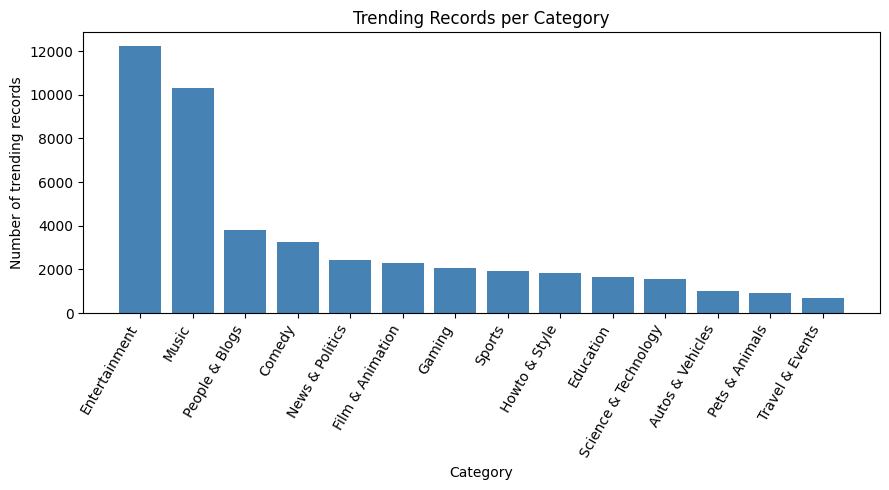

In [5]:
# Chart 1: bar chart of record counts per category
cat_counts = df["category_name"].value_counts()
plt.figure(figsize=(9, 5))
plt.bar(cat_counts.index, cat_counts.values, color="steelblue")
plt.title("Trending Records per Category")
plt.xlabel("Category")
plt.ylabel("Number of trending records")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

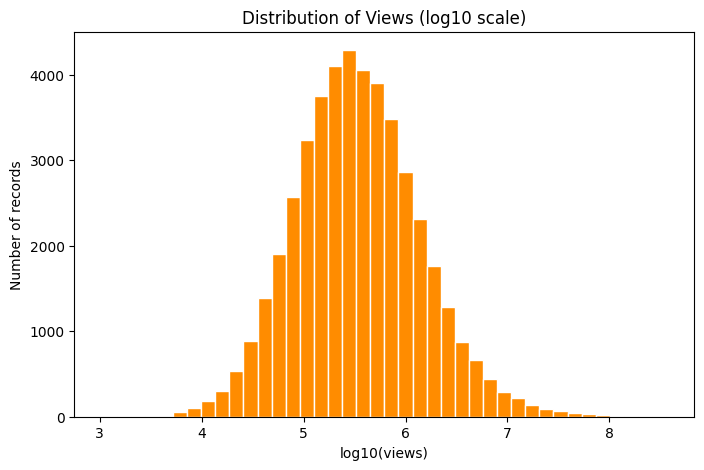

In [6]:
# Chart 2: histogram of log-scaled views
plt.figure(figsize=(8, 5))
plt.hist(np.log10(df["views"]), bins=40, color="darkorange", edgecolor="white")
plt.title("Distribution of Views (log10 scale)")
plt.xlabel("log10(views)")
plt.ylabel("Number of records")
plt.show()

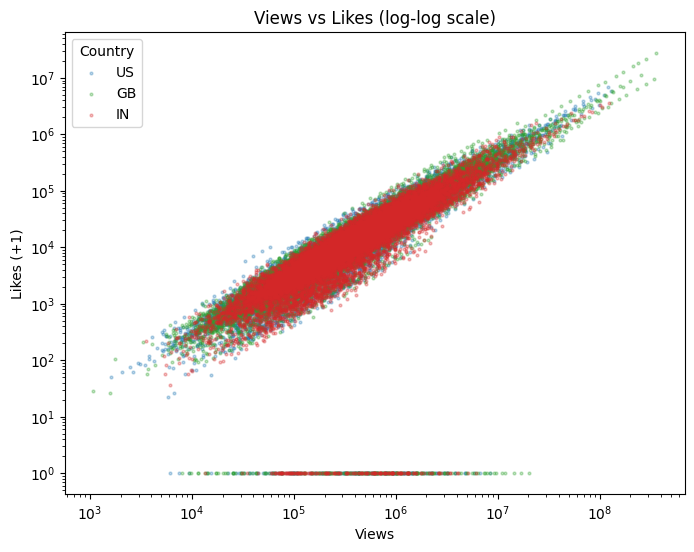

In [7]:
# Chart 3: scatter plot of views vs likes (log-log axes), coloured by country
colors = {"US": "tab:blue", "GB": "tab:green", "IN": "tab:red"}
plt.figure(figsize=(8, 6))
for country in COUNTRIES:
    sub = df[df["country"] == country]
    plt.scatter(sub["views"], sub["likes"] + 1, s=4, alpha=0.3,
                color=colors[country], label=country)
plt.xscale("log")
plt.yscale("log")
plt.title("Views vs Likes (log-log scale)")
plt.xlabel("Views")
plt.ylabel("Likes (+1)")
plt.legend(title="Country")
plt.show()

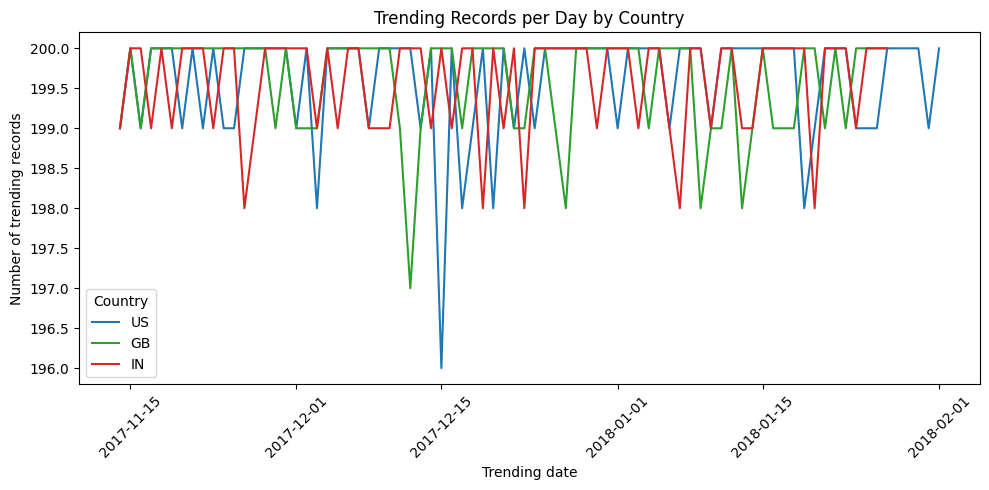

In [8]:
# Chart 4: line chart of trending records per day, one line per country
daily = df.groupby(["trending_dt", "country"]).size().unstack("country")[COUNTRIES]
plt.figure(figsize=(10, 5))
for country in COUNTRIES:
    plt.plot(daily.index, daily[country], label=country, color=colors[country])
plt.title("Trending Records per Day by Country")
plt.xlabel("Trending date")
plt.ylabel("Number of trending records")
plt.legend(title="Country")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

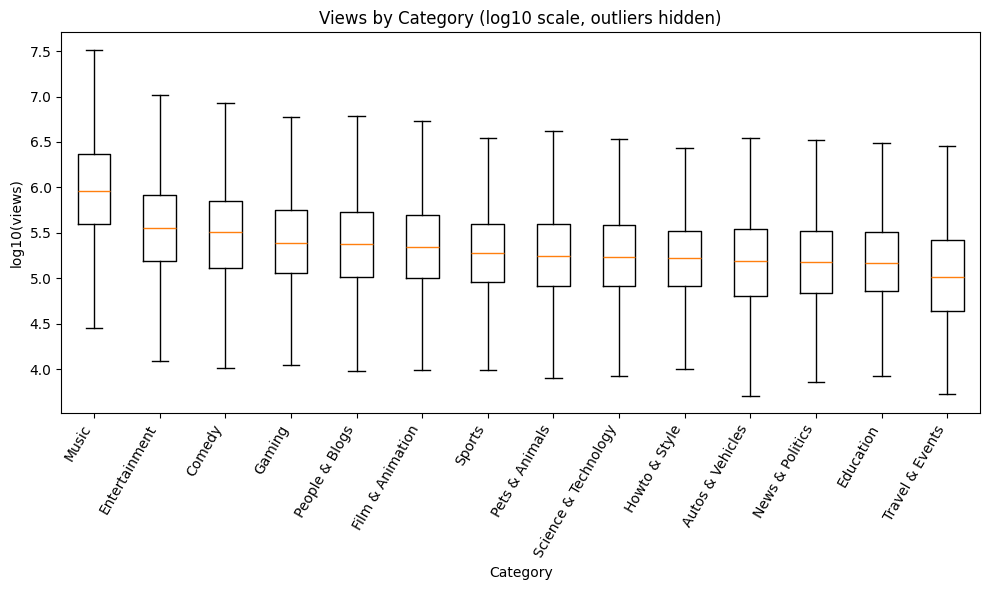

In [9]:
# Chart 5: box plot of log10(views) by category, ordered by median
order = (df.assign(log_views=np.log10(df["views"]))
           .groupby("category_name")["log_views"].median()
           .sort_values(ascending=False).index)
data = [np.log10(df.loc[df["category_name"] == c, "views"]) for c in order]

plt.figure(figsize=(10, 6))
plt.boxplot(data, tick_labels=order, showfliers=False)
plt.title("Views by Category (log10 scale, outliers hidden)")
plt.xlabel("Category")
plt.ylabel("log10(views)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 4. Interpretation of the charts

**Chart 1: Trending records per category (bar chart).** Entertainment (about 12,000 records) and Music (about 10,300) dominate trending, together making up roughly half of all records, while Travel & Events has fewer than 800. A bar chart fits because the variable is a category and the value is a count, so bar height is easy to compare.

**Chart 2: Histogram of log10 views.** Views are roughly bell-shaped on a log scale, peaking near log10 = 5.5 (about 300,000 views), with a thin tail reaching 10^8. A typical trending video therefore has a few hundred thousand views, and a very small number reach hundreds of millions. A histogram fits because views is one continuous variable and we want to see its shape; the log scale is needed because raw views are too skewed to read.

**Chart 3: Views vs likes (scatter plot, log-log).** Likes rise steadily with views in a tight band, with the same pattern in all three countries, so videos with more views almost always have more likes. The row of points at the bottom are records with zero likes, mostly videos with ratings disabled. A scatter plot fits because both variables are numeric and we want to see how one moves with the other.

**Chart 4: Trending records per day (line chart).** Each country shows about 196 to 200 records per day with small dips, so the trending list has a nearly fixed size per country and the volume tells us nothing about popularity. The dips reflect days with fewer unique records after duplicates and removed videos were taken out. A line chart fits because the x-axis is time and we are looking for trends and breaks.

**Chart 5: Views by category (box plot, log10 scale).** Music has the highest median views by a clear margin, followed by Entertainment, while Travel & Events has the lowest. The boxes overlap heavily, so category explains only part of how many views a video gets. A box plot fits because it compares the median and spread of one numeric variable across many categories; outliers are hidden for readability.

## 5. Interactive charts (Plotly)

In [10]:
import plotly.express as px

# Chart 6: scatter of views vs likes, coloured by category, title on hover
sample = df.sample(5000, random_state=42)
fig1 = px.scatter(sample, x="views", y="likes", color="category_name",
                  hover_name="title", hover_data=["country", "channel_title"],
                  log_x=True, log_y=True, opacity=0.6,
                  title="Views vs Likes by Category (random sample of 5,000 records)",
                  labels={"views": "Views", "likes": "Likes", "category_name": "Category"})
fig1.show()

In [11]:
# Chart 7: average views per category, compared across countries
avg = (df.groupby(["category_name", "country"])["views"].mean()
         .reset_index())
fig2 = px.bar(avg, x="category_name", y="views", color="country", barmode="group",
              title="Average Views per Category by Country",
              labels={"category_name": "Category", "views": "Average views",
                      "country": "Country"})
fig2.update_layout(xaxis_tickangle=-45)
fig2.show()

**Chart 6: Views vs likes, coloured by category (interactive scatter).** Hovering over a point shows the video title, country and channel. Points from every category follow the same rising band, so the link between views and likes does not depend on category; categories differ mainly in where they sit along the band, with Music further to the upper right. An interactive scatter fits because there are thousands of points and the person exploring the data wants to identify individual videos, which a static chart cannot do.

**Chart 7: Average views per category by country (interactive grouped bar chart).** Music is far ahead in all three countries, with GB highest (about 3.7 million average views), then US (about 2.9 million) and IN (about 2.5 million). Every other category averages under about 1 million views, and IN is slightly ahead of the others in Entertainment and Comedy. A grouped bar chart fits because it compares one average value across two categorical variables (category and country) side by side, and hovering gives the exact numbers.

## 6. Distributions and outliers

In [12]:
for col in ["views", "likes"]:
    s = df[col]
    mean, median = s.mean(), s.median()
    mode = s.mode().iloc[0]

    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = ((s < low) | (s > high)).sum()

    print(f"=== {col} ===")
    print(f"Mean   : {mean:,.0f}")
    print(f"Median : {median:,.0f}")
    print(f"Mode   : {mode:,.0f}")
    print(f"Q1 = {q1:,.0f}   Q3 = {q3:,.0f}   IQR = {iqr:,.0f}")
    print(f"Outlier fences: [{low:,.0f}, {high:,.0f}]")
    print(f"Outliers: {outliers:,} ({outliers / len(s) * 100:.1f}% of records)")
    print(f"Mean > median? {mean > median}")
    print()

=== views ===
Mean   : 1,180,232
Median : 318,570
Mode   : 16,000
Q1 = 129,578   Q3 = 823,936   IQR = 694,357
Outlier fences: [-911,957, 1,865,472]
Outliers: 5,073 (11.1% of records)
Mean > median? True

=== likes ===
Mean   : 45,861
Median : 10,206
Mode   : 0
Q1 = 3,652   Q3 = 28,986   IQR = 25,334
Outlier fences: [-34,348, 66,986]
Outliers: 5,255 (11.4% of records)
Mean > median? True



### Skewness

| Column | Mean | Median | Mode |
|---|---|---|---|
| views | 1,180,232 | 318,570 | 16,000 |
| likes | 45,861 | 10,206 | 0 |

For both columns mean > median > mode, so both distributions are **right-skewed**: a long tail of very popular videos pulls the mean far above the median, while most videos sit at lower values. The median is the better measure of a typical video here.

### Outliers (IQR rule: outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR)

| Column | Fences | Outliers | Share |
|---|---|---|---|
| views | -911,957 to 1,865,472 | 5,073 | 11.1% |
| likes | -34,348 to 66,986 | 5,255 | 11.4% |

All outliers lie above the upper fence, because the lower fences are negative. **Decision: keep them.** They are not errors; they are the genuinely viral videos, and understanding what trends is the purpose of this analysis. Removing them would delete about 11% of the records and erase exactly the videos we want to study. Where they would distort a chart, we use a log scale or the median instead of deleting them.

## 7. Correlation

               views  likes  dislikes  comment_count  days_to_trend
views          1.000  0.921     0.889          0.916          0.196
likes          0.921  1.000     0.868          0.812          0.160
dislikes       0.889  0.868     1.000          0.889          0.196
comment_count  0.916  0.812     0.889          1.000          0.207
days_to_trend  0.196  0.160     0.196          0.207          1.000


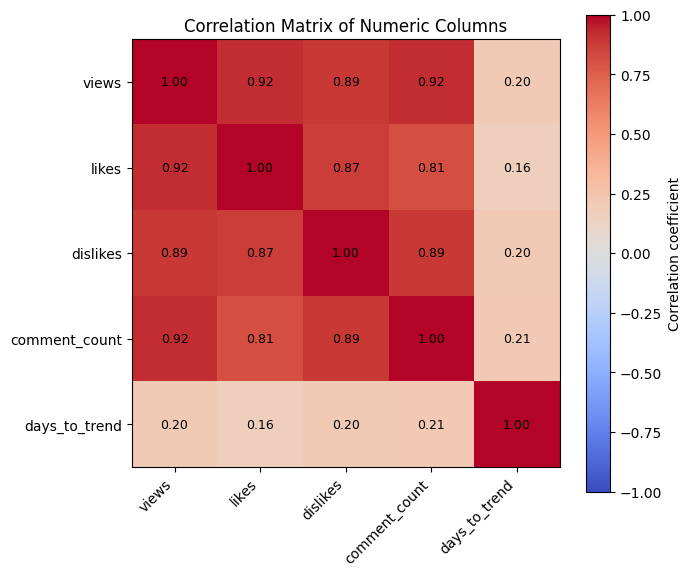


Strongest pairs (absolute correlation):
views     likes            0.921
          comment_count    0.916
dislikes  comment_count    0.889
views     dislikes         0.889
dtype: float64


In [13]:
num_cols = ["views", "likes", "dislikes", "comment_count", "days_to_trend"]
corr = df[num_cols].corr()
print(corr.round(3))

# Heatmap with Matplotlib
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, label="Correlation coefficient")
ax.set_title("Correlation Matrix of Numeric Columns")
plt.tight_layout()
plt.show()

# The two strongest pairs: largest absolute off-diagonal values
pairs = (corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().sort_values(ascending=False))
print("\nStrongest pairs (absolute correlation):")
print(pairs.head(4).round(3))

### Correlation interpretation

**Heatmap:** the correlation matrix covers views, likes, dislikes, comment count and days_to_trend. A heatmap fits because it shows every pairwise relationship at once, with colour and number in each square.

**Two strongest correlations (largest absolute off-diagonal coefficients):**
1. **Views and likes: 0.921.** Videos with more views almost always have more likes, so likes rise steadily with audience size.
2. **Views and comment count: 0.916.** More-viewed videos also attract more comments, almost as strongly as they attract likes.

Dislikes also move with views (0.889), so all four engagement counts rise together with popularity. The only weak links involve days_to_trend (0.16 to 0.21): how quickly a video reaches trending says very little about how many views or likes it gets.

**Correlation is not causation:** a high correlation between likes and views does not prove that likes cause views. Both are driven by the same underlying factor, the size of the audience that watched the video, and views could just as well cause likes as the other way round.

## 8. Funnel analysis

In [14]:
# One row per unique video (video_id across all countries), using peak values
videos = (df.groupby("video_id")
            .agg(peak_views=("views", "max"),
                 peak_comments=("comment_count", "max"))
            .reset_index())

median_peak = videos["peak_views"].median()
p90_peak = videos["peak_views"].quantile(0.90)

stage1 = videos
stage2 = stage1[stage1["peak_views"] > median_peak]
stage3 = stage2[stage2["peak_views"] > p90_peak]
stage4 = stage3[stage3["peak_comments"] >= 1000]

stages = [("1. All videos that ever trended", stage1),
          ("2. Above the median peak views", stage2),
          ("3. Above the 90th percentile of peak views", stage3),
          ("4. 1,000+ comments (within stage 3)", stage4)]

funnel = pd.DataFrame({
    "Stage": [name for name, _ in stages],
    "Videos": [len(s) for _, s in stages],
})
funnel["Conversion from previous stage (%)"] = (funnel["Videos"] / funnel["Videos"].shift(1) * 100).round(1)
funnel["Share of all videos (%)"] = (funnel["Videos"] / funnel["Videos"].iloc[0] * 100).round(1)

print(f"Median peak views: {median_peak:,.0f}   90th percentile: {p90_peak:,.0f}")
print()
print(funnel.to_string(index=False))

Median peak views: 265,290   90th percentile: 1,646,845

                                     Stage  Videos  Conversion from previous stage (%)  Share of all videos (%)
           1. All videos that ever trended   14688                                 NaN                    100.0
            2. Above the median peak views    7344                                50.0                     50.0
3. Above the 90th percentile of peak views    1469                                20.0                     10.0
       4. 1,000+ comments (within stage 3)    1440                                98.0                      9.8


In [15]:
print(funnel[["Stage", "Videos", "Conversion from previous stage (%)", "Share of all videos (%)"]].to_string(index=False))

                                     Stage  Videos  Conversion from previous stage (%)  Share of all videos (%)
           1. All videos that ever trended   14688                                 NaN                    100.0
            2. Above the median peak views    7344                                50.0                     50.0
3. Above the 90th percentile of peak views    1469                                20.0                     10.0
       4. 1,000+ comments (within stage 3)    1440                                98.0                      9.8


In [16]:
short = funnel.copy()
short.columns = ["Stage", "Videos", "Conv_%", "Share_%"]
short["Stage"] = ["1 All trended", "2 Above median", "3 Above P90", "4 1000+ comments"]
print(short.to_string(index=False))

           Stage  Videos  Conv_%  Share_%
   1 All trended   14688     NaN    100.0
  2 Above median    7344    50.0     50.0
     3 Above P90    1469    20.0     10.0
4 1000+ comments    1440    98.0      9.8


### Funnel results

| Stage | Videos | Conversion from previous stage | Share of all videos |
|---|---|---|---|
| 1. All videos that ever trended | 14,688 | - | 100.0% |
| 2. Above the median peak views (265,290) | 7,344 | 50.0% | 50.0% |
| 3. Above the 90th percentile of peak views (1,646,845) | 1,469 | 20.0% | 10.0% |
| 4. 1,000+ comments (within stage 3) | 1,440 | 98.0% | 9.8% |

**Largest drop-off:** from stage 2 to stage 3, where only 20.0% of the above-median videos go on to pass the 90th percentile. (The 50% drop in stage 1 to 2 is not a real finding, because the median splits any list in half by definition.)

**What it suggests:** getting past the median is easy, but reaching very high view counts is rare, so a trending spot does not guarantee a hit. Once a video does reach the top 10% by views, it almost always attracts a large audience of commenters too (98.0%), which means that high reach and high engagement go together. For a content team, the real challenge is the step from "trending" to "breakout", not the step from "average" to "above average".

## 9. Retention-style analysis (trending lifespan)

Retention by country (% of videos still on the list):
         All     US     GB     IN
day 1  100.0  100.0  100.0  100.0
day 2   62.8   64.8   68.8   56.8
day 3   41.6   43.5   49.1   34.7
day 5   19.2   20.1   25.8   13.7
day 7    9.7   10.8   14.2    5.6

Retention by category:
       Music  Entertainment  News & Politics
day 1  100.0          100.0            100.0
day 2   79.8           69.9             40.4
day 3   64.8           50.7             16.1
day 5   42.8           26.3              3.7
day 7   28.8           13.2              0.9


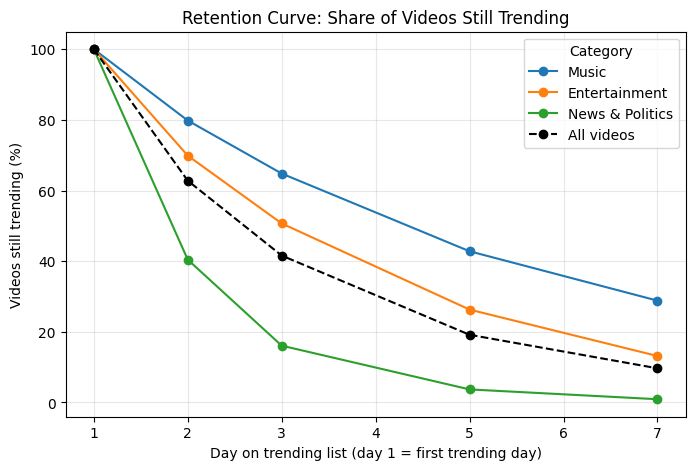

In [17]:
# Per country + video: the set of days (day 1 = first trending day)
first_day = df.groupby(["country", "video_id"])["trending_dt"].transform("min")
df["day_number"] = (df["trending_dt"] - first_day).dt.days + 1

# Unique videos per country and category
video_info = df.drop_duplicates(["country", "video_id"])[["country", "video_id", "category_name"]]
days_seen = df.groupby(["country", "video_id"])["day_number"].apply(set).reset_index(name="days")
vids = video_info.merge(days_seen, on=["country", "video_id"])

check_days = [1, 2, 3, 5, 7]

def retention(frame):
    n = len(frame)
    return [sum(d in days for days in frame["days"]) / n * 100 for d in check_days]

# Overall and by country
result = {"All": retention(vids)}
for c in COUNTRIES:
    result[c] = retention(vids[vids["country"] == c])
ret_country = pd.DataFrame(result, index=[f"day {d}" for d in check_days]).round(1)
print("Retention by country (% of videos still on the list):")
print(ret_country)

# Compare categories (Music vs News & Politics)
cats = ["Music", "Entertainment", "News & Politics"]
ret_cat = pd.DataFrame({c: retention(vids[vids["category_name"] == c]) for c in cats},
                       index=[f"day {d}" for d in check_days]).round(1)
print("\nRetention by category:")
print(ret_cat)

# Retention curve
plt.figure(figsize=(8, 5))
for c in cats:
    plt.plot(check_days, retention(vids[vids["category_name"] == c]), marker="o", label=c)
plt.plot(check_days, retention(vids), marker="o", linestyle="--", color="black", label="All videos")
plt.title("Retention Curve: Share of Videos Still Trending")
plt.xlabel("Day on trending list (day 1 = first trending day)")
plt.ylabel("Videos still trending (%)")
plt.legend(title="Category")
plt.grid(alpha=0.3)
plt.show()

### Retention results (day 1 = first trending day)

**Overall and by country (% of unique videos still on the list):**

| Day | All | US | GB | IN |
|---|---|---|---|---|
| Day 2 | 62.8% | 64.8% | 68.8% | 56.8% |
| Day 3 | 41.6% | 43.5% | 49.1% | 34.7% |
| Day 5 | 19.2% | 20.1% | 25.8% | 13.7% |
| Day 7 | 9.7% | 10.8% | 14.2% | 5.6% |

**By category:**

| Day | Music | Entertainment | News & Politics |
|---|---|---|---|
| Day 2 | 79.8% | 69.9% | 40.4% |
| Day 3 | 64.8% | 50.7% | 16.1% |
| Day 5 | 42.8% | 26.3% | 3.7% |
| Day 7 | 28.8% | 13.2% | 0.9% |

**Comparison:** the retention curve falls steeply in every group: only about 63% of videos survive to day 2 and under 10% reach day 7. Music videos stay the longest (28.8% still trending on day 7), while News & Politics videos disappear almost at once (40.4% on day 2 and under 1% on day 7). Across countries, GB keeps videos the longest (14.2% on day 7) and IN the shortest (5.6%).

**Which videos stay and which vanish:** videos that stay tend to be Music and Entertainment content, where interest builds up and lasts for days, while news content is time-sensitive and drops off the list as soon as the story is over. A large part of every group disappears after one day, so a single day of trending is the normal outcome.

## 10. Cohort view

In [18]:
# One row per video and country: first trending day, lifespan, peak views
per_video = (df.groupby(["country", "video_id"])
               .agg(first_day=("trending_dt", "min"),
                    lifespan=("trending_dt", "nunique"),
                    peak_views=("views", "max"))
               .reset_index())

# Cohort = the week in which the video first trended
per_video["cohort_week"] = per_video["first_day"].dt.to_period("W").dt.start_time.dt.date

cohorts = (per_video.groupby("cohort_week")
                    .agg(videos=("video_id", "count"),
                         avg_peak_views=("peak_views", "mean"),
                         avg_lifespan=("lifespan", "mean"))
                    .round(2))
cohorts["avg_peak_views"] = cohorts["avg_peak_views"].round(0).astype(int)
print(cohorts)

             videos  avg_peak_views  avg_lifespan
cohort_week                                      
2017-11-13     1607         1059522          3.20
2017-11-20     1326         1246998          3.20
2017-11-27     1318         1105586          3.11
2017-12-04     1323          841227          3.24
2017-12-11     1327         1223118          3.08
2017-12-18     1375          903201          3.15
2017-12-25     1297          925304          3.15
2018-01-01     1349         1268137          3.12
2018-01-08     1356          833168          3.14
2018-01-15     1320          653157          3.02
2018-01-22     1196          570474          2.32
2018-01-29      253          343430          1.69


### Cohort results

Cohorts are the week in which a video first trended. Cohorts from 2017-11-13 to 2018-01-15 look alike: about 1,300 videos each, an average lifespan of 3.0 to 3.2 days, and average peak views that move between about 650,000 and 1.27 million without a trend.

**The last two cohorts look different.** The cohort of 2018-01-22 has an average lifespan of 2.32 days (against about 3.1 for earlier weeks), and the cohort of 2018-01-29 has only 253 videos and an average lifespan of 1.69 days, with the lowest average peak views (343,430).

**Is the difference real?** Mostly no. It is explained by the fixed time window of the data: the dataset ends in early February 2018, so videos that first trended in the final weeks are cut off before they have had time to stay on the list (their lifespan is truncated), and the last cohort is only a partial week with far fewer videos (253 against about 1,300). The comparison of those two cohorts with the others is therefore not fair, and the earlier cohorts show no real change over time.

In [19]:
share = (df["category_name"].value_counts(normalize=True) * 100).round(1)
print("Top 2 category shares (%):", share.head(2).to_dict(), "| together:", round(share.head(2).sum(), 1))
print("Median days_to_trend:", df["days_to_trend"].median(), "| mean:", round(df["days_to_trend"].mean(), 2))
print("Share of records trending within 3 days of publishing:",
      round((df["days_to_trend"] <= 3).mean() * 100, 1), "%")
print("Records per country:", df["country"].value_counts().to_dict())
print("Average views by country:", df.groupby("country")["views"].mean().round(0).to_dict())
print("Date range:", df["trending_dt"].min().date(), "to", df["trending_dt"].max().date())

Top 2 category shares (%): {'Entertainment': 26.7, 'Music': 22.4} | together: 49.1
Median days_to_trend: 3.0 | mean: 5.09
Share of records trending within 3 days of publishing: 55.3 %
Records per country: {'US': 15968, 'GB': 14970, 'IN': 14970}
Average views by country: {'GB': 1583959.0, 'IN': 953217.0, 'US': 1014564.0}
Date range: 2017-11-14 to 2018-02-01


## 11. Content strategy briefing

Entertainment (26.7% of trending records) and Music (22.4%) together make up about half of everything on the trending list, so these two categories dominate. Videos reach trending quickly: the median video trends 3 days after publishing, and 55.3% trend within 3 days. What separates videos that stay from those that vanish is mainly category: 28.8% of Music videos are still trending on day 7, against only 0.9% of News & Politics videos, and only 9.7% of all videos last that long. Music also stands out on reach, with the highest average views of any category in all three countries. Countries differ as well: GB has the highest average views per record (about 1.58 million) and keeps videos on the list longest (14.2% still trending on day 7), while IN has the lowest average views (about 0.95 million) and the shortest retention (5.6% on day 7). A video that trends is far from guaranteed a breakout, because only 20% of above-median videos go on to pass the 90th percentile of peak views. One limitation is that the data covers only 14 November 2017 to 1 February 2018 and only videos that did trend, so we cannot say what keeps a video from trending at all, and lifespans for videos that first trended near the end of the window are cut short.